In [2]:
from dotenv import load_dotenv
import os 
load_dotenv()

if os.getenv("OPENAI_API_KEY") is None:
    print("Not set")
else:
    print("API SET")

API SET


In [3]:
from typing import TypedDict , Literal

class llm_schema(TypedDict):

    topic: Literal["Technial","billing","general"]
    

class graph_schema(TypedDict):

    user_input:str
    topic: str
    mssg: list

In [4]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-5-mini")
llmSchema = llm.with_structured_output(llm_schema)

In [5]:
from langchain_core.prompts import ChatPromptTemplate

def decider(state:graph_schema):

    topic = llmSchema.invoke(state['user_input'])['topic']

    return {"topic":topic}

def frtechnical(state:graph_schema):

    user_input=state["user_input"]


    prompt= ChatPromptTemplate.from_messages([
                ("system","You are a technical support node which help user in technial difficulties"),
                ("human","Tell Me {query}")
    ])

    chain = prompt | llm 

    response = chain.invoke({"query":user_input}).content 

    return {"mssg":response}


def frbilling(state:graph_schema):

    user_input=state["user_input"]


    prompt= ChatPromptTemplate.from_messages([
                ("system","You are a billing support node which help user in billing difficulties such as payments etc"),
                ("human","Tell Me {query}")
    ])

    chain = prompt | llm 

    response = chain.invoke({"query":user_input}).content 

    return {"mssg":response}

def frgeneral(state:graph_schema):

    user_input=state["user_input"]


    prompt= ChatPromptTemplate.from_messages([
                ("system","You are a gernal casual support node which help user in all over difficulties"),
                ("human","Tell Me {query}")
    ])

    chain = prompt | llm 

    response = chain.invoke({"query":user_input}).content 

    return {"mssg":response}


def route(state:graph_schema):

    if state["topic"].lower()=="technical":
        return "technical"
    
    elif state["topic"].lower()=="billing":
        return "billing"
    
    elif state["topic"].lower()=="general":
        return "general"

In [6]:
from langgraph.graph import StateGraph , START , END

graph = StateGraph(graph_schema)

graph.add_node("decider",decider)
graph.add_node("frtechnical",frtechnical)
graph.add_node("frbilling",frbilling)
graph.add_node("frgeneral",frgeneral)

graph.add_edge(START,"decider")
graph.add_conditional_edges("decider",route,{"technical":"frtechnical","billing":"frbilling","general":"frgeneral"})
graph.add_edge("frtechnical",END)
graph.add_edge("frbilling",END)
graph.add_edge("frgeneral",END)

jarvis = graph.compile()

In [ ]:
jarvis.invoke({
    "user_input":"",
    "topic":"",
    "mssg":""})

{'user_input': 'My payment is stuck not able to payment smoothly',
 'topic': 'billing',
 'mssg': 'Sorry you’re having trouble — I can help. To start, I need a few details so I can check what happened and escalate if needed:\n\nPlease provide:\n- Account email or username\n- Order ID or invoice number (if you have one)\n- Date/time of the payment attempt (and your time zone)\n- Payment method used (card, PayPal, Apple/Google Pay, bank transfer, etc.) — for cards, just the last 4 digits\n- Any error message shown (exact text) or a screenshot\n- Device & where you tried (web browser name + version, or iOS/Android app)\n\nImmediate things you can try right now (quick checklist)\n- Check your bank/statement for a “pending” authorization — it may appear but not be fully processed. Pending holds usually drop off in 24–7 days depending on the bank.\n- Make sure card details are correct (expiry, billing address), card has available balance, and 3D Secure / OTP pop-up didn’t get blocked.\n- If i

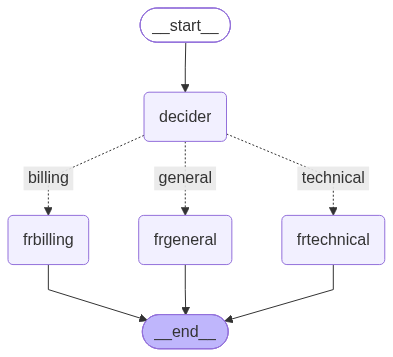

In [8]:
from IPython.display import Image

Image(jarvis.get_graph().draw_mermaid_png())